# Entrega 1 — Recomendador secuencial para H&M con Transformers
**Machine Learning no supervisado (C2)** · Líneas base del curso → SASRec → comparación @K

**Usuaria y decisión.** Una clienta de H&M online que acaba de comprar algo. La decisión que apoya el recomendador:
*qué 10 prendas mostrarle en "Completa tu look" o en el correo de la semana*.

Contenido:
1. Configuración
2. Datos y limpieza
3. Exploración y hallazgos
4. Protocolo de evaluación (leave-last-out + métricas verificadas a mano)
5. Líneas base: popularidad, reglas de asociación, ítem–ítem coseno
6. SASRec en PyTorch: bloques, pérdida, entrenamiento y selección de configuración
7. Comparación final en prueba: métricas, cobertura y costo
8. Segmentos
9. Tres clientas: historial, recomendación y pesos de atención
10. Embeddings de prendas por categoría
11. Conclusión: ¿vale la pena el Transformer?

Archivos de entrada: `data/secuencias.parquet`, `data/mapa_items.csv`, `data/interacciones.parquet`
(generados por `scripts/preparar_hm.py`). Salidas: `data/metricas.csv`, `modelos/sasrec.pt`.

## 1. Configuración

In [1]:
# Instala las librerías que usa el notebook (solo hace algo la primera vez)
%pip install -q pandas pyarrow scipy matplotlib jinja2 mlxtend scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, time, math, collections, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fn

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
# Carpeta raíz del proyecto: funciona abriendo el notebook desde notebooks/ o desde la raíz
RAIZ = next(p for p in (Path(".."), Path(".")) if (p / "data" / "secuencias.parquet").exists())
DATA = RAIZ / "data"
MODELOS = RAIZ / "modelos"
MODELOS.mkdir(exist_ok=True)
KS = (5, 10, 20)

# Estilo de gráficos: marcas finas, grilla suave, sin bordes superiores/derechos
AZUL, NARANJO, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": GRIS, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.prop_cycle": plt.cycler(color=[AZUL, NARANJO, AQUA, AMARILLO, MAGENTA]),
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print(f"PyTorch {torch.__version__} · hilos de CPU: {torch.get_num_threads()}")

PyTorch 2.15.0+cu132 · hilos de CPU: 2


## 2. Datos y limpieza

**Base:** *H&M Personalized Fashion Recommendations* (Kaggle). 31,8 millones de compras online
(sep-2018 a sep-2020) con fecha, cliente, prenda, precio y canal; catálogo de 105.542 prendas con atributos.

**Decisiones de limpieza** (en `scripts/preparar_hm.py`):

| Paso | Decisión | Motivo |
|---|---|---|
| Período | 23-mar-2020 a 22-sep-2020 (6 meses) | La moda cambia rápido; el catálogo vigente es lo relevante |
| Muestra | 10 % fijo de clientes (por hash del `customer_id`) | Entrenar en un computador normal; siempre la misma muestra |
| Duplicados | Varias unidades de la misma prenda, mismo cliente, mismo día = 1 interacción | Una compra de 3 calcetines iguales no son 3 decisiones |
| Recompras | Se conservan si son en días distintos | Son decisiones nuevas |
| Filtro | 5-core (usuarios e ítems con ≥ 5) + usuarios con compras en ≥ 2 días distintos | Mínimo del enunciado; sin clientas de un solo carrito |
| Orden | Por fecha; dentro del mismo día, el orden del archivo original | H&M registra solo la fecha, no la hora |
| Índices | Desde 1; el 0 queda como relleno | Requisito del enunciado y de SASRec |

In [3]:
resumen = json.load(open(DATA / "resumen_preparacion.json"))
seq = pd.read_parquet(DATA / "secuencias.parquet")
mapa = pd.read_csv(DATA / "mapa_items.csv")
inter = pd.read_parquet(DATA / "interacciones.parquet")

N_ITEMS = int(mapa.item_idx.max())
N_USERS = len(seq)
S = [np.asarray(x, dtype=np.int64) for x in seq["items"]]          # secuencia de ítems por usuaria
F = [np.asarray(x, dtype="datetime64[D]") for x in seq["fechas"]]  # fecha de cada ítem
nombre = dict(zip(mapa.item_idx, mapa.prod_name + " (" + mapa.product_type_name + ", " + mapa.colour_group_name + ")"))

assert N_USERS >= 2000 and N_ITEMS >= 500 and len(inter) >= 50_000, "No cumple los mínimos"
pd.Series({
    "Filas originales": resumen["filas_originales"],
    "Tras filtro de fecha y muestra": resumen["tras_filtro_fecha_y_muestra"],
    "Duplicados del mismo día eliminados": resumen["duplicados_mismo_dia"],
    "Interacciones finales": resumen["interacciones"],
    "Usuarias": resumen["usuarios"],
    "Ítems (prendas)": resumen["items"],
}).to_frame("valor").style.format("{:,.0f}")

,valor
Filas originales,"31,788,324"
Tras filtro de fecha y muestra,"817,642"
Duplicados del mismo día eliminados,"80,115"
Interacciones finales,"579,226"
Usuarias,"36,168"
Ítems (prendas),"17,801"


In [4]:
mapa[["item_idx", "prod_name", "product_type_name", "colour_group_name", "index_group_name", "precio_mediano"]].head()

,item_idx,prod_name,product_type_name,colour_group_name,index_group_name,precio_mediano
0,1,Strap top,Vest top,White,Ladieswear,0.0085
1,2,20 den 1p Stockings,Underwear Tights,Black,Ladieswear,0.0072
2,3,Shape Up 30 den 1p Tights,Leggings/Tights,Black,Ladieswear,0.0117
3,4,Support 40 den 1p Tights,Underwear Tights,Black,Ladieswear,0.0113
4,5,200 den 1p Tights,Underwear Tights,Black,Ladieswear,0.0085


## 3. Exploración

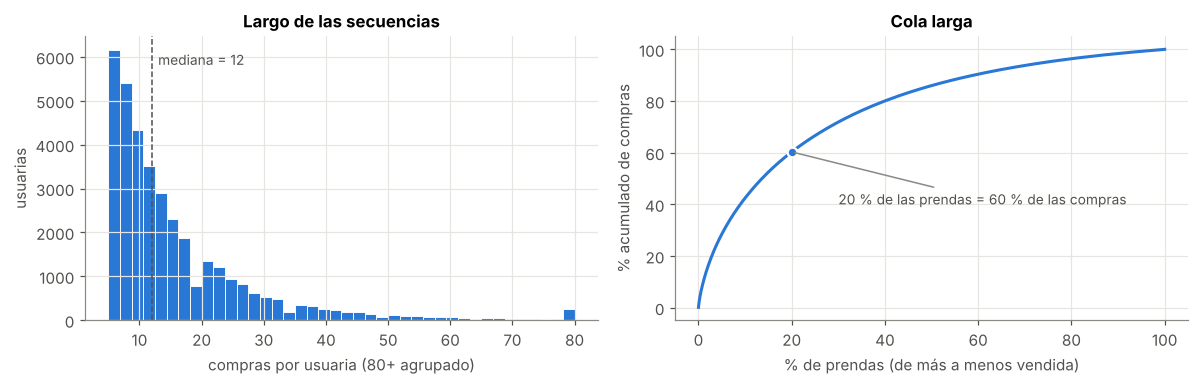

Densidad: 0.0900%  |  largo medio 16.0, mediana 12, p90 31
Prendas con < 10 compras: 29.5%
Días de compra por usuaria: mediana 4, p90 9
Pasos consecutivos el mismo día ('carrito'): 74.3%
Recompras (misma prenda otro día): 4.6%


In [5]:
largos = np.array([len(s) for s in S])
pop_total = inter.item_idx.value_counts()
dens = len(inter) / (N_USERS * N_ITEMS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.clip(largos, 0, 80), bins=40, color=AZUL, edgecolor="white", linewidth=0.6)
ax[0].set(title="Largo de las secuencias", xlabel="compras por usuaria (80+ agrupado)", ylabel="usuarias")
ax[0].axvline(np.median(largos), color="#52514e", lw=1, ls="--")
ax[0].text(np.median(largos) + 1, ax[0].get_ylim()[1] * 0.9, f"mediana = {np.median(largos):.0f}", color="#52514e", fontsize=9)

acum = np.cumsum(pop_total.values) / pop_total.sum()
x = np.arange(1, len(acum) + 1) / len(acum)
ax[1].plot(x * 100, acum * 100, color=AZUL, lw=2)
i20 = int(0.2 * len(acum)) - 1
ax[1].scatter([20], [acum[i20] * 100], color=AZUL, s=40, zorder=3, edgecolor="white", linewidth=1.5)
ax[1].annotate(f"20 % de las prendas = {acum[i20]*100:.0f} % de las compras", (20, acum[i20] * 100),
               xytext=(30, 40), fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color=GRIS))
ax[1].set(title="Cola larga", xlabel="% de prendas (de más a menos vendida)", ylabel="% acumulado de compras")
plt.tight_layout(); plt.show()

dias = np.array([len(np.unique(f)) for f in F])
mismo_dia = np.mean(np.concatenate([np.diff(f.astype(np.int64)) == 0 for f in F]))
print(f"Densidad: {dens:.4%}  |  largo medio {largos.mean():.1f}, mediana {np.median(largos):.0f}, p90 {np.percentile(largos, 90):.0f}")
print(f"Prendas con < 10 compras: {(pop_total < 10).mean():.1%}")
print(f"Días de compra por usuaria: mediana {np.median(dias):.0f}, p90 {np.percentile(dias, 90):.0f}")
print(f"Pasos consecutivos el mismo día ('carrito'): {mismo_dia:.1%}")
print(f"Recompras (misma prenda otro día): {inter.duplicated(['user_idx', 'item_idx']).mean():.1%}")

In [6]:
lineas = inter.merge(mapa[["item_idx", "index_group_name", "product_type_name"]], on="item_idx")
(lineas.index_group_name.value_counts(normalize=True).mul(100).round(1).rename("% de compras").to_frame().T)

index_group_name,Ladieswear,Divided,Menswear,Sport,Baby/Children
% de compras,68.6000,21.5000,5.2000,4.1000,0.6000


### Evidencia de que el orden importa

Dos pruebas simples, sin modelo:

1. **Transiciones entre días.** Contamos qué se compra el día siguiente a cada prenda (con las compras de entrenamiento).
   Luego predecimos lo que la clienta compra en su **último día** usando las transiciones desde (a) su día de compra
   anterior, (b) un día al azar de su historial, (c) su primer día. Si el orden no importara, las tres darían lo mismo.
2. **Tipo de prenda consecutivo.** ¿Con qué frecuencia la compra siguiente es del mismo tipo de prenda que la anterior,
   comparado con lo que se esperaría al azar?

In [7]:
rng = np.random.default_rng(SEED)
trans = collections.defaultdict(collections.Counter)
for it, f in zip(S, F):
    ud = np.unique(f)
    if len(ud) < 2: continue
    tr, trf = it[f < ud[-1]], f[f < ud[-1]]
    dd = np.unique(trf)
    for a, b in zip(dd[:-1], dd[1:]):
        for x in tr[trf == a]:
            trans[x].update(tr[trf == b].tolist())

aciertos = {"día anterior": 0, "día al azar": 0, "primer día": 0}; n = 0
for it, f in zip(S, F):
    ud = np.unique(f)
    if len(ud) < 3: continue
    n += 1
    objetivo, hist = set(it[f == ud[-1]]), set(it[f < ud[-1]])
    for clave, dia in (("día anterior", ud[-2]), ("día al azar", ud[rng.integers(0, len(ud) - 1)]), ("primer día", ud[0])):
        c = collections.Counter()
        for x in it[f == dia]: c.update(trans[x])
        top = [j for j, _ in c.most_common(10 + len(hist)) if j not in hist][:10]
        aciertos[clave] += bool(objetivo & set(top))
orden = pd.Series({k: v / n for k, v in aciertos.items()}, name="HR@10 último día")

tipo = dict(zip(mapa.item_idx, mapa.product_type_name))
pares = [(tipo[a], tipo[b]) for s in S for a, b in zip(s[:-1], s[1:])]
igual = np.mean([a == b for a, b in pares])
azar = (lineas.product_type_name.value_counts(normalize=True) ** 2).sum()

display(orden.to_frame().T)
print(f"Usuarias evaluadas: {n:,}. Día anterior vs primer día: {orden.iloc[0] / orden.iloc[2] - 1:+.0%}")
print(f"Compra siguiente del mismo tipo de prenda: {igual:.1%} (al azar: {azar:.1%}, {igual/azar:.1f} veces más)")

,día anterior,día al azar,primer día
HR@10 último día,0.0263,0.0196,0.0160


Usuarias evaluadas: 27,327. Día anterior vs primer día: +64%
Compra siguiente del mismo tipo de prenda: 22.0% (al azar: 6.1%, 3.6 veces más)


### Hallazgos

1. **Muy dispersa y con cola larga.** Densidad de 0,09 %: cada clienta compró una fracción mínima del catálogo. El 20 % de las prendas concentra el 60 % de las compras y casi 3 de cada 10 prendas tienen menos de 10 compras. Un modelo de popularidad deja fuera casi todo el catálogo.
2. **Se compra en carritos.** El 74 % de las compras consecutivas ocurre el mismo día, y en el 70 % de las clientas el ítem de validación y el de prueba son del mismo carrito. El orden *entre días* es real; *dentro* del día, no se conoce.
3. **El orden importa.** Lo comprado el día anterior predice el último día un 64 % mejor que lo del primer día (HR@10 2,6 % vs 1,6 %), y la compra siguiente es del mismo tipo de prenda 3,6 veces más seguido que al azar (22 % vs 6 %). En la sección 5.3, dar más peso a las últimas compras (λ = 0,8) mejora el NDCG@10 de ítem–ítem en 28 %.
4. **La moda es temporal.** La popularidad de los últimos 3 días casi duplica a la popularidad de todo el período (HR@10 1,6 % vs 1,0 % en validación), y mientras más corta la ventana, mejor. Lo que se vende cambia de una semana a otra.
5. **Catálogo sesgado y variantes de color.** El 69 % de las compras es Ladieswear y solo el 0,6 % es infantil. Cada prenda existe en ≈ 2 colores en promedio, y los modelos de co-ocurrencia tienden a recomendar la misma prenda en otros colores: buena precisión, poca variedad.

## 4. Protocolo de evaluación

**Partición leave-last-out por usuaria**, idéntica para todos los modelos:
- **Prueba:** el último ítem de cada usuaria.
- **Validación:** el penúltimo.
- **Entrenamiento:** el resto.

Los modelos se ajustan solo con entrenamiento. Para predecir el ítem de validación ven el historial de entrenamiento; para
predecir el de prueba ven entrenamiento + validación (igual que SASRec.pytorch). Los hiperparámetros se eligen en validación,
y la prueba se mira **una sola vez** al final (sección 7).

**Ranking completo:** cada modelo ordena las 17.801 prendas (no una muestra de 100 negativos, como hace `evaluate()` en
SASRec.pytorch). Se excluyen las prendas que la clienta ya compró: en "Completa tu look" no tiene sentido mostrarle lo que ya tiene.
El costo es que, si el ítem de prueba es una recompra (≈ 8 % de los casos), cuenta como fallo para todos los modelos por igual.
Los empates de puntaje se resuelven con el rango promedio.

**Métricas**, con `rank` = posición del ítem real (1 = primero):
- HitRate@K = 1 si `rank ≤ K`
- NDCG@K = 1 / log₂(rank + 1) si `rank ≤ K`, si no 0 (con un solo ítem relevante, el ideal es 1)
- MRR = 1 / rank (sin corte)
- Cobertura@10 = % del catálogo que aparece en algún top-10

**Advertencia del dominio:** como H&M no registra la hora, en una parte de las clientas el ítem de validación y el de
prueba son del mismo día (mismo carrito). Ahí la tarea es *completar el carrito*; cuando son de días distintos,
es *predecir la próxima visita*. En la sección 8 se miden por separado.

In [8]:
train = [s[:-2] for s in S]
hist_val, val_t = train, np.array([s[-2] for s in S])
hist_test, test_t = [s[:-1] for s in S], np.array([s[-1] for s in S])
fecha_val = np.array([f[-2] for f in F]); fecha_test = np.array([f[-1] for f in F])
mismo_carrito = fecha_val == fecha_test

print(f"Interacciones de entrenamiento: {sum(map(len, train)):,}")
print(f"Usuarias con validación y prueba el mismo día: {mismo_carrito.mean():.1%}")
print(f"Objetivos de prueba que son recompra: {np.mean([t in set(h) for h, t in zip(hist_test, test_t)]):.1%}")

Interacciones de entrenamiento: 506,890
Usuarias con validación y prueba el mismo día: 70.2%
Objetivos de prueba que son recompra: 8.3%


In [9]:
def evaluar(score_fn, hists, targets, bs=2048):
    # Ranking completo con exclusión de lo ya comprado.
    # score_fn(lista_de_historiales) -> matriz (usuarias x N_ITEMS+1); la columna 0 es relleno.
    ranks = np.empty(len(hists)); top10 = []; t0 = time.perf_counter()
    for i in range(0, len(hists), bs):
        H = hists[i:i + bs]
        sc = np.asarray(score_fn(H), dtype=np.float64)
        sc[:, 0] = -np.inf
        filas = np.repeat(np.arange(len(H)), [len(h) for h in H])
        sc[filas, np.concatenate(H)] = -np.inf                        # excluir lo ya comprado
        st = sc[np.arange(len(H)), targets[i:i + bs]]
        mayores = (sc > st[:, None]).sum(1)
        empates = (sc == st[:, None]).sum(1) - 1
        r = 1 + mayores + empates / 2                                  # rango promedio en empates
        ranks[i:i + bs] = np.where(np.isinf(st), np.inf, r)            # recompra excluida = fallo
        top10.append(np.argpartition(-sc, 10, axis=1)[:, :10].copy())  # copia: no retener la matriz completa
    seg = time.perf_counter() - t0
    m = {f"HR@{k}": np.mean(ranks <= k) for k in KS}
    m |= {f"NDCG@{k}": np.mean(np.where(ranks <= k, 1 / np.log2(ranks + 1), 0)) for k in KS}
    m["MRR"] = np.mean(1 / ranks)
    m["Cobertura@10"] = len(np.unique(np.concatenate(top10))) / N_ITEMS
    m["ms_por_1000_usuarias"] = 1000 * seg / len(hists) * 1000
    return m, ranks

def matriz_binaria(hists):
    filas = np.repeat(np.arange(len(hists)), [len(h) for h in hists])
    X = sp.csr_matrix((np.ones(len(filas), np.float32), (filas, np.concatenate(hists))),
                      shape=(len(hists), N_ITEMS + 1))
    X.sum_duplicates(); X.data[:] = 1
    return X

X_train = matriz_binaria(train)
pop = np.asarray(X_train.sum(0)).ravel().astype(np.float32)   # compras por prenda en entrenamiento
desempate = 1e-6 * pop / pop.max()                            # desempate por popularidad para todos los modelos
COLS = [f"HR@{k}" for k in KS] + [f"NDCG@{k}" for k in KS] + ["MRR", "Cobertura@10"]

# Prueba de `evaluar` con un caso conocido: puntaje = -índice, así la prenda 1 es la favorita
_juguete = lambda H: np.tile(-np.arange(N_ITEMS + 1, dtype=np.float32), (len(H), 1))
_, _r = evaluar(_juguete, [np.array([1]), np.array([2])], np.array([3, 1]))
# clienta 1 ya compró la 1 (se excluye) → la 3 queda 2.ª; clienta 2 compró la 2 → la 1 queda 1.ª
print("Prueba de evaluar: rangos", _r.tolist(), "(esperado [2.0, 1.0])")
assert _r.tolist() == [2.0, 1.0]
print(f"Matriz de entrenamiento: {X_train.nnz:,} pares clienta–prenda · prendas con compras: {(pop > 0).sum():,}")


Prueba de evaluar: rangos [2.0, 1.0] (esperado [2.0, 1.0])
Matriz de entrenamiento: 485,120 pares clienta–prenda · prendas con compras: 17,794


## 5. Líneas base

### 5.1 Popularidad
- **Global:** las prendas más compradas en todo el entrenamiento.
- **Reciente:** las más compradas en los *w* días anteriores a la fecha que se quiere predecir (con compras de todas las
  clientas, solo anteriores a esa fecha). Prueba si en moda importa *cuándo*, no solo *qué*.

In [10]:
resultados_val, ajuste, parametros = {}, {}, {}

t0 = time.perf_counter()
score_pop = lambda H: np.tile(pop + 0, (len(H), 1))
ajuste["Popularidad global"] = time.perf_counter() - t0
parametros["Popularidad global"] = N_ITEMS
resultados_val["Popularidad global"], _ = evaluar(score_pop, hist_val, val_t)

t0 = time.perf_counter()
dia0 = inter.t_dat.min()
d_idx = (inter.t_dat - dia0).dt.days.values
N_DIAS = d_idx.max() + 2
diario = sp.csr_matrix((np.ones(len(inter), np.float32), (d_idx, inter.item_idx.values)),
                       shape=(N_DIAS, N_ITEMS + 1)).toarray()
acum_dia = np.vstack([np.zeros((1, N_ITEMS + 1), np.float32), np.cumsum(diario, 0)])  # acum_dia[d] = días < d
ajuste["Popularidad reciente"] = time.perf_counter() - t0
parametros["Popularidad reciente"] = int(N_DIAS * N_ITEMS)

def score_reciente_factory(fechas, w):
    dias_obj = (fechas - np.datetime64(dia0.date())).astype(int)
    estado = {"i": 0}
    def f(H):
        i = estado["i"]; d = dias_obj[i:i + len(H)]; estado["i"] += len(H)
        return acum_dia[d] - acum_dia[np.maximum(d - w, 0)] + desempate
    return f

ventanas = {w: evaluar(score_reciente_factory(fecha_val, w), hist_val, val_t)[0] for w in (3, 7, 14, 30)}
tabla_w = pd.DataFrame(ventanas).T[["HR@10", "NDCG@10", "MRR"]]; tabla_w.index.name = "ventana (días)"
W_BEST = int(tabla_w["NDCG@10"].idxmax())
resultados_val["Popularidad reciente"] = ventanas[W_BEST]
display(tabla_w)
print(f"Ventana elegida en validación: {W_BEST} días")

,HR@10,NDCG@10,MRR
ventana (días),,,
3,0.0158,0.0076,0.0084
7,0.0135,0.0068,0.0080
14,0.0139,0.0065,0.0074
30,0.0119,0.0054,0.0064


Ventana elegida en validación: 3 días


### 5.2 Reglas de asociación 
1. Cada secuencia de entrenamiento es **una canasta** (sin orden), codificada como tabla 0/1.
2. **FP-Growth** (`mlxtend`) encuentra los itemsets frecuentes y `association_rules` genera las reglas, dejando solo las
   de **un consecuente**. Antecedentes de hasta 2 prendas (`max_len = 3`).
3. Para recomendar se **activan** las reglas cuyo antecedente está completo dentro de la canasta de la clienta, se descartan
   las que recomiendan algo que ya compró y se ordena por **lift** (desempate por confianza), una regla por prenda.
4. Si faltan sugerencias (arranque en frío), se completa con los **más vendidos**.

soporte = P(X ∩ Z) · confianza = P(X ∩ Z) / P(X) · lift = confianza / P(Z)

Con 17.801 prendas, los soportes son muy bajos, así que el umbral se expresa como **conteo mínimo** de canastas
(`min_conteo`); junto con la confianza mínima se eligen en validación.

In [11]:
from mlxtend.frequent_patterns import fpgrowth, association_rules

t0 = time.perf_counter()
_X = X_train[:, 1:]
_vivas = np.asarray(_X.sum(0)).ravel() > 0
# mlxtend exige nombres de columna de texto en tablas dispersas
canastas = pd.DataFrame.sparse.from_spmatrix(_X[:, _vivas].astype(bool),
                                             columns=[str(i) for i in np.arange(1, N_ITEMS + 1)[_vivas]])
t_canastas = time.perf_counter() - t0
print(f"Canastas: {canastas.shape[0]:,} × {canastas.shape[1]:,} prendas")

def minar_reglas(min_conteo, min_conf):
    frecuentes = fpgrowth(canastas, min_support=min_conteo / len(canastas), use_colnames=True, max_len=3)
    reglas = association_rules(frecuentes, metric="confidence", min_threshold=min_conf)
    reglas = reglas[reglas["consequents"].apply(len) == 1].copy()                 # un solo consecuente
    reglas["producto"] = reglas["consequents"].apply(lambda z: int(next(iter(z))))
    reglas["antecedente"] = reglas["antecedents"].apply(lambda a: tuple(sorted(int(x) for x in a)))
    return reglas.reset_index(drop=True)

def score_reglas_factory(reglas):
    # Puntaje = lift de la mejor regla activa (+ confianza como desempate); sin regla = más vendidos
    valor = (reglas["lift"] + 1e-6 * reglas["confidence"]).values
    ant_len = reglas["antecedente"].apply(len).values
    r1, r2 = np.where(ant_len == 1)[0], np.where(ant_len == 2)[0]
    a1 = np.array([reglas["antecedente"].iat[i][0] for i in r1], dtype=np.int64)
    L1 = sp.csr_matrix((valor[r1], (a1, reglas["producto"].values[r1])), shape=(N_ITEMS + 1, N_ITEMS + 1))
    a2 = np.array([reglas["antecedente"].iat[i] for i in r2], dtype=np.int64).reshape(-1, 2)
    c2, v2 = reglas["producto"].values[r2], valor[r2]
    relleno = 1e-3 * pop / pop.max()          # más vendidos: siempre por debajo de cualquier regla activa
    def f(H):
        out = np.zeros((len(H), N_ITEMS + 1))
        for i, h in enumerate(H):             # reglas {A} ⇒ {Z}: A está en la canasta
            sub = L1[np.unique(h)]
            if sub.nnz: out[i] = sub.max(axis=0).toarray().ravel()
        if len(r2):                           # reglas {A, B} ⇒ {Z}: A y B están en la canasta
            Xh = matriz_binaria(H).tocsc()
            act = Xh[:, a2[:, 0]].multiply(Xh[:, a2[:, 1]]).tocoo()
            np.maximum.at(out, (act.row, c2[act.col]), v2[act.col])
        return out + relleno
    return f

grid_reglas = {}
for mc in (3, 5, 10, 20):
    for mconf in (0.0, 0.1):
        reglas = minar_reglas(mc, mconf)
        res, rk = evaluar(score_reglas_factory(reglas), hist_val, val_t)
        res["n_reglas"] = len(reglas)
        grid_reglas[(mc, mconf)] = res
tabla_r = pd.DataFrame(grid_reglas).T[["n_reglas", "HR@10", "NDCG@10", "MRR", "Cobertura@10"]]
tabla_r.index.names = ["min_conteo", "min_confianza"]
MC_BEST, CONF_BEST = tabla_r["NDCG@10"].idxmax()

t0 = time.perf_counter(); REGLAS = minar_reglas(MC_BEST, CONF_BEST)
ajuste["Reglas de asociación"] = t_canastas + time.perf_counter() - t0
parametros["Reglas de asociación"] = len(REGLAS)
resultados_val["Reglas de asociación"] = grid_reglas[(MC_BEST, CONF_BEST)]
display(tabla_r.style.format({"n_reglas": "{:,.0f}", "HR@10": "{:.4f}", "NDCG@10": "{:.4f}", "MRR": "{:.4f}", "Cobertura@10": "{:.1%}"}))
print(f"Elegido: min_conteo = {MC_BEST}, confianza mínima = {CONF_BEST}  →  {len(REGLAS):,} reglas "
      f"({(REGLAS.antecedente.apply(len) == 2).sum():,} con antecedente de 2 prendas)")

# ¿A cuántas clientas se les activa al menos una regla? (en el Certamen 2: '% casos con regla activa')
antecedentes_1 = set(a[0] for a in REGLAS.antecedente if len(a) == 1)
con_regla = np.mean([not antecedentes_1.isdisjoint(h) for h in hist_val])
print(f"Clientas con al menos una regla activa (validación): {con_regla:.1%}")

top_reglas = REGLAS.sort_values("lift", ascending=False).head(5)
pd.DataFrame({
    "regla": [" + ".join(nombre[a] for a in r.antecedente) + "  ⇒  " + nombre[r.producto] for r in top_reglas.itertuples()],
    "soporte": top_reglas["support"].values, "confianza": top_reglas["confidence"].values, "lift": top_reglas["lift"].values,
})

Canastas: 36,168 × 17,794 prendas


Elegido: min_conteo = 5, confianza mínima = 0.1  →  17,199 reglas (7,184 con antecedente de 2 prendas)
Clientas con al menos una regla activa (validación): 97.6%


,regla,soporte,confianza,lift
0,"Zoey bikini top (Bikini top, Light Yellow) ⇒ ...",0.0001,1.0000,"5,166.8571"
1,"ZARA highwaist bikini bottom (Swimwear bottom,...",0.0001,0.7143,"5,166.8571"
2,"Festival Aria Skirt (Skirt, Orange) ⇒ Festiv...",0.0002,0.6667,"4,018.6667"
3,"Festival Penelope (Blouse, Orange) ⇒ Festiva...",0.0002,1.0000,"4,018.6667"
4,"Harry tie Tanga (Swimwear bottom, White) ⇒ H...",0.0002,0.7500,"3,875.1429"


### 5.3 Ítem–ítem con coseno, ponderando los últimos ítems
Similitud coseno entre prendas según qué clientas las compraron: sim(a, b) = co-ocurrencias(a, b) / √(compras(a)·compras(b)).
Se guardan los 100 vecinos más parecidos de cada prenda.

Puntaje de una candidata *c* para una clienta con historial h₁ … h_L:

  score(c) = Σⱼ λ^(L−j) · sim(hⱼ, c)

Con λ = 1 todas las compras pesan igual (bolsa de ítems). Con λ < 1 las últimas pesan más: es la única línea base
que usa el orden. λ se elige en validación.

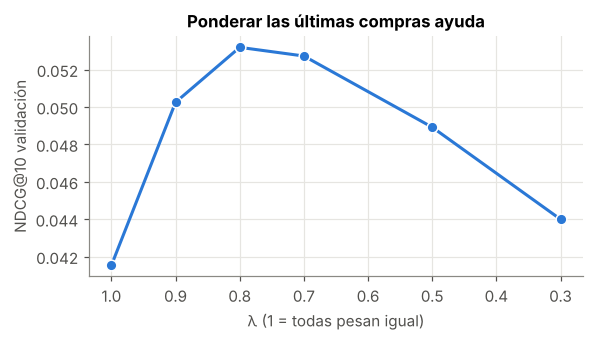

,HR@10,NDCG@10,MRR,Cobertura@10
λ,,,,
1.0000,0.0629,0.0415,0.0376,0.8897
0.9000,0.0742,0.0502,0.0457,0.9037
0.8000,0.0779,0.0532,0.0482,0.9217
0.7000,0.0761,0.0527,0.0481,0.9328
0.5000,0.0698,0.0489,0.0449,0.9380
0.3000,0.0627,0.0440,0.0405,0.9339


λ elegido: 0.8.  Mejora de NDCG@10 sobre λ = 1: +28%


In [12]:
t0 = time.perf_counter()
CO = (X_train.T @ X_train).tocsr(); CO.setdiag(0); CO.eliminate_zeros()

def vecinos_coseno(topn=100):
    c = CO.tocoo()
    sim = (c.data / np.sqrt(pop[c.row] * pop[c.col])).astype(np.float32)
    M = sp.csr_matrix((sim, (c.row, c.col)), shape=CO.shape)
    filas, cols, vals = [], [], []
    for i in range(M.shape[0]):
        a, b = M.indptr[i], M.indptr[i + 1]
        if a == b: continue
        v, cc = M.data[a:b], M.indices[a:b]
        if b - a > topn:
            k = np.argpartition(-v, topn)[:topn]; v, cc = v[k], cc[k]
        filas.append(np.full(len(cc), i)); cols.append(cc); vals.append(v)
    return sp.csr_matrix((np.concatenate(vals), (np.concatenate(filas), np.concatenate(cols))), shape=M.shape)

SIM = vecinos_coseno(100)
ajuste["Ítem–ítem coseno"] = time.perf_counter() - t0
parametros["Ítem–ítem coseno"] = SIM.nnz

def score_knn_factory(lam):
    def f(H):
        filas = np.repeat(np.arange(len(H)), [len(h) for h in H])
        w = np.concatenate([lam ** np.arange(len(h) - 1, -1, -1) for h in H]).astype(np.float32)
        W = sp.csr_matrix((w, (filas, np.concatenate(H))), shape=(len(H), N_ITEMS + 1))
        return (W @ SIM).toarray() + desempate
    return f

grid_knn = {lam: evaluar(score_knn_factory(lam), hist_val, val_t)[0] for lam in (1.0, 0.9, 0.8, 0.7, 0.5, 0.3)}
tabla_k = pd.DataFrame(grid_knn).T[["HR@10", "NDCG@10", "MRR", "Cobertura@10"]]; tabla_k.index.name = "λ"
LAM_BEST = float(tabla_k["NDCG@10"].idxmax())
resultados_val["Ítem–ítem coseno"] = grid_knn[LAM_BEST]

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(tabla_k.index, tabla_k["NDCG@10"], color=AZUL, lw=2, marker="o", markersize=7, markeredgecolor="white")
ax.set(title="Ponderar las últimas compras ayuda", xlabel="λ (1 = todas pesan igual)", ylabel="NDCG@10 validación")
ax.invert_xaxis(); plt.tight_layout(); plt.show()
display(tabla_k)
print(f"λ elegido: {LAM_BEST}.  Mejora de NDCG@10 sobre λ = 1: {tabla_k.loc[LAM_BEST, 'NDCG@10'] / tabla_k.loc[1.0, 'NDCG@10'] - 1:+.0%}")

### Verificación a mano de las métricas en una usuaria
Tomamos una clienta, calculamos el ranking del ítem real de prueba con ítem–ítem y recalculamos las métricas con las
fórmulas, para comprobar que coinciden con la función `evaluar`.

In [13]:
_, ranks_knn_test = evaluar(score_knn_factory(LAM_BEST), hist_test, test_t)
u = int(np.where((ranks_knn_test > 1) & (ranks_knn_test <= 10))[0][0])
h, t = hist_test[u], test_t[u]

sc = score_knn_factory(LAM_BEST)([h])[0].astype(np.float64)
sc[0] = -np.inf; sc[h] = -np.inf
orden_items = np.argsort(-sc)
rank_mano = int(np.where(orden_items == t)[0][0]) + 1

print(f"Usuaria {u + 1}: {len(h)} compras previas. Últimas 3:")
for x in h[-3:]: print("   ", nombre[x])
print(f"Ítem real de prueba: {nombre[t]}")
print("\nTop 10 recomendado:")
for i, x in enumerate(orden_items[:10], 1): print(f"  {i:>2}. {nombre[x]}" + ("   ← ítem real" if x == t else ""))

calc = {"rank": rank_mano, "HR@5": int(rank_mano <= 5), "HR@10": int(rank_mano <= 10), "HR@20": int(rank_mano <= 20),
        "NDCG@10 = 1/log2(rank+1)": 1 / np.log2(rank_mano + 1) if rank_mano <= 10 else 0.0, "MRR = 1/rank": 1 / rank_mano}
print("\nA mano:", {k: round(float(v), 4) for k, v in calc.items()})
r_fn = ranks_knn_test[u]
print("Función:", {"rank": r_fn, "HR@10": int(r_fn <= 10), "NDCG@10": round(1 / np.log2(r_fn + 1), 4), "MRR": round(1 / r_fn, 4)})
assert rank_mano == r_fn

Usuaria 60: 4 compras previas. Últimas 3:
    Sandy ss (T-shirt, White)
    Jodi skirt (Skirt, Black)
    Mimosa soft top bea pad (Bra, Light Blue)
Ítem real de prueba: Prima (Vest top, Black)

Top 10 recomendado:
   1. Mimosa soft top bea pad (Bra, Light Green)
   2. Mimosa soft top bea pad (Bra, White)
   3. Mimosa soft top bea pad (Bra, Light Pink)
   4. Cool Kennedy necklace (Necklace, Gold)
   5. Prima (Vest top, Black)   ← ítem real
   6. EMELIE DOUBLE EYELET BELT (Belt, White)
   7. Tassle pile coat (Jacket, Light Grey)
   8. Mimosa Dahlia Hipster (Underwear bottom, Light Blue)
   9. Alfia top (Top, Black)
  10. Rico dress SPEED (Dress, Yellowish Brown)

A mano: {'rank': 5.0, 'HR@5': 1.0, 'HR@10': 1.0, 'HR@20': 1.0, 'NDCG@10 = 1/log2(rank+1)': 0.3869, 'MRR = 1/rank': 0.2}
Función: {'rank': np.float64(5.0), 'HR@10': 1, 'NDCG@10': np.float64(0.3869), 'MRR': np.float64(0.2)}


## 6. SASRec en PyTorch

**Idea.** SASRec (Kang & McAuley, 2018) trata el historial como una oración y predice la siguiente "palabra" (prenda)
con un bloque tipo **decodificador de Transformer** (como GPT): en cada posición *t* solo puede mirar las posiciones ≤ *t*.

```
historial (últimas 50 compras, relleno con 0 a la izquierda)
   │
   ▼
[1] embedding de la prenda  +  embedding de la posición
   │
   ▼  ┌──────────── bloque × N ────────────┐
   │  │ [2] LayerNorm → auto-atención causal (Q, K, V, máscara triangular) → + residual
   │  │ [3] LayerNorm → feed-forward (Linear → ReLU → Linear)              → + residual
   │  └────────────────────────────────────┘
   ▼
[4] LayerNorm final → vector h_t de la clienta en cada posición
   │
   ▼
puntaje(prenda i) = h_t · e_i   (producto punto con el mismo embedding de entrada)
```

Partimos de la arquitectura de SASRec.pytorch (pmixer), pero la reescribimos para explicar cada pieza, extraer los pesos de
atención y evaluar con ranking completo. Las diferencias con el repositorio están marcadas en el código.

### 6.1 Bloque [2]: auto-atención causal
Para cada posición se calculan tres proyecciones de su vector: **consulta** Q (qué busco), **clave** K (qué ofrezco) y
**valor** V (qué información entrego). El peso con que la posición *t* mira a la posición *j* es

  α_tj = softmax_j( Q_t · K_j / √d_k )

y la salida es Σⱼ α_tj · V_j. Dos máscaras ponen −∞ antes del softmax:
- **Causal (triangular superior):** *t* no puede mirar posiciones futuras *j > t* (no hay trampa: no ve lo que va a predecir).
- **Relleno:** nadie mira las posiciones con índice 0.

Con varias **cabezas**, esto se hace en paralelo en subespacios de dimensión d/cabezas, y cada cabeza puede especializarse
(por ejemplo, una mira la compra anterior y otra el tipo de prenda dominante). Los α son los **pesos de atención** de la sección 9.

In [14]:
class AtencionCausal(nn.Module):
    def __init__(self, d, cabezas, dropout):
        super().__init__()
        assert d % cabezas == 0
        self.h, self.dk = cabezas, d // cabezas
        self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.o = nn.Linear(d, d)                       # mezcla las cabezas
        self.drop = nn.Dropout(dropout)

    def forward(self, x, relleno):
        B, L, D = x.shape
        dividir = lambda t: t.view(B, L, self.h, self.dk).transpose(1, 2)        # (B, cabezas, L, dk)
        q, k, v = dividir(self.q(x)), dividir(self.k(x)), dividir(self.v(x))
        a = q @ k.transpose(-1, -2) / math.sqrt(self.dk)                         # (B, cabezas, L, L)
        futuro = torch.triu(torch.ones(L, L, dtype=torch.bool, device=x.device), diagonal=1)
        a = a.masked_fill(futuro, float("-inf"))                                 # máscara causal triangular
        a = a.masked_fill(relleno[:, None, None, :], float("-inf"))              # no mirar el relleno
        pesos = torch.softmax(a, dim=-1).nan_to_num(0.0)                         # filas de relleno quedan en 0
        salida = (self.drop(pesos) @ v).transpose(1, 2).reshape(B, L, D)
        return self.o(salida), pesos

# Verificación: con la máscara causal nadie mira el futuro y nadie mira el relleno
_att = AtencionCausal(d=8, cabezas=2, dropout=0.0)
_x = torch.randn(1, 5, 8)
_rell = torch.tensor([[True, False, False, False, False]])      # posición 0 = relleno
_, _w = _att(_x, _rell)
print("Pesos de atención de la cabeza 1 (fila = posición que mira, columna = posición mirada):")
print(_w[0, 0].detach().numpy().round(2))
assert torch.all(torch.triu(_w[0], diagonal=1) == 0) and torch.all(_w[0, :, :, 0] == 0)
print("OK: triángulo superior en 0 (no mira el futuro), columna del relleno en 0 y cada fila real suma 1")


Pesos de atención de la cabeza 1 (fila = posición que mira, columna = posición mirada):
[[0.   0.   0.   0.   0.  ]
 [0.   1.   0.   0.   0.  ]
 [0.   0.54 0.46 0.   0.  ]
 [0.   0.29 0.41 0.3  0.  ]
 [0.   0.18 0.24 0.21 0.37]]


OK: triángulo superior en 0 (no mira el futuro), columna del relleno en 0 y cada fila real suma 1


### 6.2 Bloque [3]: Transformer con residual, normalización y feed-forward
- **LayerNorm antes de cada sub-capa** (*pre-norm*, la variante que SASRec.pytorch agregó en 2025 porque entrena más estable).
- **Conexión residual:** x + subcapa(x). Permite apilar bloques sin que se pierda la señal original del embedding.
- **Feed-forward por posición:** Linear(d→d) → ReLU → Linear(d→d). La atención *mezcla* posiciones; el feed-forward
  *transforma* cada posición por separado (agrega no linealidad).
- **Dropout** en atención, feed-forward y embeddings para no sobreajustar (hay pocas compras por clienta).

In [15]:
class BloqueTransformer(nn.Module):
    def __init__(self, d, cabezas, dropout):
        super().__init__()
        self.norm1, self.atencion = nn.LayerNorm(d), AtencionCausal(d, cabezas, dropout)
        self.norm2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, relleno):
        a, pesos = self.atencion(self.norm1(x), relleno)
        x = x + self.drop(a)                        # residual 1
        x = x + self.drop(self.ff(self.norm2(x)))   # residual 2
        return x, pesos

_bloque = BloqueTransformer(d=8, cabezas=2, dropout=0.0)
_y, _w = _bloque(_x, _rell)
print(f"Bloque: entrada {tuple(_x.shape)} → salida {tuple(_y.shape)} (misma forma, por eso se pueden apilar) · pesos {tuple(_w.shape)} = (lote, cabezas, L, L)")


Bloque: entrada (1, 5, 8) → salida (1, 5, 8) (misma forma, por eso se pueden apilar) · pesos (1, 2, 5, 5) = (lote, cabezas, L, L)


### 6.3 Bloques [1] y [4]: embeddings y modelo completo
- **Embedding de prenda** (`padding_idx = 0`): un vector de dimensión *d* por prenda. Es el mismo que se usa a la salida
  para puntuar (pesos compartidos, como en SASRec), así que las prendas quedan en un espacio donde "cerca = se compran en secuencia".
  Se multiplica por √d antes de sumar la posición, igual que en SASRec.pytorch.
- **Embedding de posición** (aprendido): sin él, la atención no distingue el orden (sería otra vez una bolsa de ítems).
  La posición 49 es siempre la compra más reciente, porque el relleno va a la izquierda.
- Inicialización normal con desviación 0,02 (como GPT); con la inicialización por defecto la pérdida inicial era enorme.

In [16]:
class SASRec(nn.Module):
    def __init__(self, n_items, d=64, bloques=2, cabezas=1, dropout=0.2, maxlen=50):
        super().__init__()
        self.d, self.maxlen = d, maxlen
        self.item = nn.Embedding(n_items + 1, d, padding_idx=0)
        self.pos = nn.Embedding(maxlen, d)
        self.drop = nn.Dropout(dropout)
        self.bloques = nn.ModuleList([BloqueTransformer(d, cabezas, dropout) for _ in range(bloques)])
        self.norm = nn.LayerNorm(d)
        nn.init.normal_(self.item.weight, std=0.02); nn.init.normal_(self.pos.weight, std=0.02)
        with torch.no_grad(): self.item.weight[0].zero_()

    def forward(self, s):                                          # s: (B, L) índices de prenda, 0 = relleno
        relleno = s == 0
        x = self.item(s) * math.sqrt(self.d) + self.pos(torch.arange(s.shape[1], device=s.device))[None]
        x = self.drop(x) * (~relleno)[..., None]
        pesos = []
        for bloque in self.bloques:
            x, w = bloque(x, relleno)
            x = x * (~relleno)[..., None]
            pesos.append(w)
        return self.norm(x), pesos                                  # (B, L, d) y pesos de atención por bloque

    def puntajes(self, s):                                          # puntaje de todas las prendas para la última posición
        h, _ = self.forward(s)
        return h[:, -1] @ self.item.weight.T

MAXLEN = 50   # cubre al 90 % de las historias completas (p90 = 31)

def lote(seqs, maxlen=MAXLEN):
    X = np.zeros((len(seqs), maxlen), np.int64)
    for i, s in enumerate(seqs):
        s = s[-maxlen:]; X[i, maxlen - len(s):] = s               # relleno a la izquierda
    return torch.from_numpy(X)

_m = SASRec(N_ITEMS, d=64, bloques=1, cabezas=1, maxlen=MAXLEN)
_s = lote(train[:3]); _h, _ = _m(_s)
print(f"SASRec de prueba (1 bloque, d = 64): {sum(p.numel() for p in _m.parameters()):,} parámetros, "
      f"{_m.item.weight.numel():,} de ellos en el embedding de prendas")
print(f"3 historiales {tuple(_s.shape)} → vectores {tuple(_h.shape)} → puntajes {tuple(_m.puntajes(_s).shape)} (una columna por prenda + relleno)")
print("Últimas 8 posiciones del primer historial (relleno = 0 a la izquierda):", _s[0, -8:].tolist())


SASRec de prueba (1 bloque, d = 64): 1,167,872 parámetros, 1,139,328 de ellos en el embedding de prendas
3 historiales (3, 50) → vectores (3, 50, 64) → puntajes (3, 17802) (una columna por prenda + relleno)
Últimas 8 posiciones del primer historial (relleno = 0 a la izquierda): [2606, 15975, 14081, 9929, 13500, 16394, 16906, 17228]


### 6.4 Pérdida: entrenamiento estilo GPT
Cada secuencia de entrenamiento s₁ … s_L genera L−1 ejemplos a la vez: con la entrada s₁ … s_{L−1}, la salida en la
posición *t* debe predecir s_{t+1} (gracias a la máscara causal, no ve s_{t+1}). Comparamos dos pérdidas:

- **BCE con 1 negativo** (la de SASRec original y del repositorio): por cada posición, sube el puntaje del ítem real y baja
  el de 1 prenda al azar. Es barata, pero cada paso aprende contra un solo "rival" fácil.
- **Entropía cruzada sobre todo el catálogo**: softmax sobre las 17.801 prendas y −log p(ítem real). Optimiza
  exactamente lo que se evalúa: que el ítem real quede **arriba de todas las demás** en el ranking completo. Es más cara
  (≈ 4× por época en CPU), pero trabajos recientes muestran que mejora mucho a SASRec (Klenitskiy & Vasilev, RecSys 2023).

La configuración D usa BCE para medir esta diferencia con todo lo demás igual a la B.

In [17]:
def epoca(modelo, opt, perdida, batch):
    modelo.train()
    idx = np.random.permutation(len(train)); total, n = 0.0, 0
    for i in range(0, len(idx), batch):
        b = [train[j] for j in idx[i:i + batch]]
        X, Y = lote([s[:-1] for s in b]), lote([s[1:] for s in b])    # entrada y siguiente ítem (desplazado en 1)
        h, _ = modelo(X)
        m = Y > 0; hh, y = h[m], Y[m]                                  # solo posiciones reales
        if perdida == "ce":
            logits = hh @ modelo.item.weight.T
            logits[:, 0] = float("-inf")                               # el relleno nunca es una respuesta
            loss = Fn.cross_entropy(logits, y)
        else:
            neg = torch.randint(1, N_ITEMS + 1, y.shape)
            pos_l, neg_l = (hh * modelo.item(y)).sum(-1), (hh * modelo.item(neg)).sum(-1)
            loss = (Fn.binary_cross_entropy_with_logits(pos_l, torch.ones_like(pos_l)) +
                    Fn.binary_cross_entropy_with_logits(neg_l, torch.zeros_like(neg_l)))
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def validar(modelo, bs=4096):
    # HR@10 y NDCG@10 en validación (ranking completo, excluye lo comprado) para la parada temprana
    modelo.eval(); hr = nd = 0.0
    for i in range(0, len(hist_val), bs):
        H = hist_val[i:i + bs]
        sc = modelo.puntajes(lote(H)); sc[:, 0] = float("-inf")
        filas = torch.from_numpy(np.repeat(np.arange(len(H)), [len(x) for x in H]))
        sc[filas, torch.from_numpy(np.concatenate(H))] = float("-inf")
        t = torch.from_numpy(val_t[i:i + bs])
        st = sc[torch.arange(len(H)), t]
        r = 1 + (sc > st[:, None]).sum(1).float()
        r = torch.where(torch.isinf(st), torch.full_like(r, float("inf")), r)
        hr += (r <= 10).sum().item(); nd += torch.where(r <= 10, 1 / torch.log2(r + 1), torch.zeros_like(r)).sum().item()
    return hr / len(hist_val), nd / len(hist_val)

RUTA_HIST = MODELOS / "historial_sasrec.json"
HIST = json.load(open(RUTA_HIST)) if RUTA_HIST.exists() else {}

def entrenar_sasrec(clave, cfg, max_epocas=30, paciencia=3):
    ruta = MODELOS / f"sasrec_{clave}.pt"
    arq = {k: cfg[k] for k in ("d", "bloques", "cabezas", "dropout")}
    if HIST.get(clave, {}).get("terminado") and not ruta.exists():  # entrenada, pero solo se guardó la elegida
        print(f"[{clave}] entrenada antes; se conserva solo su registro (el modelo guardado es el de la configuración elegida):")
        for linea in HIST[clave]["log"]: print("   ", linea)
        return None
    if ruta.exists() and HIST.get(clave, {}).get("terminado"):       # ya entrenado: se carga (entrenar toma ~1 h en CPU)
        print(f"[{clave}] modelo ya entrenado, se carga de {ruta.name}. Registro del entrenamiento:")
        for linea in HIST[clave]["log"]: print("   ", linea)
        modelo = SASRec(N_ITEMS, maxlen=MAXLEN, **arq)
        modelo.load_state_dict(torch.load(ruta, map_location="cpu")["estado"])
        return modelo.eval()
    torch.manual_seed(SEED); np.random.seed(SEED)
    modelo = SASRec(N_ITEMS, maxlen=MAXLEN, **arq)
    opt = torch.optim.Adam(modelo.parameters(), lr=cfg["lr"])
    curvas = {"epoca": [], "perdida": [], "hr10_val": [], "ndcg10_val": [], "segundos": []}
    mejor, mejor_ep, sin_mejora, log = -1.0, 0, 0, []
    for ep in range(1, max_epocas + 1):
        t0 = time.perf_counter()
        perdida = epoca(modelo, opt, cfg["perdida"], cfg["batch"])
        hr, nd = validar(modelo)
        seg = time.perf_counter() - t0
        for k_, v_ in zip(curvas, (ep, perdida, hr, nd, seg)): curvas[k_].append(v_)
        if nd > mejor:
            mejor, mejor_ep, sin_mejora = nd, ep, 0
            torch.save({"estado": modelo.state_dict(), "cfg": cfg, "n_items": N_ITEMS, "maxlen": MAXLEN}, ruta)
        else:
            sin_mejora += 1
        linea = f"época {ep:2d} | pérdida {perdida:.4f} | val HR@10 {hr:.4f} NDCG@10 {nd:.4f} | {seg:.0f} s"
        print(f"[{clave}] {linea}", flush=True); log.append(linea)
        HIST[clave] = {"cfg": cfg, "curvas": curvas, "log": log, "mejor_epoca": mejor_ep, "terminado": False,
                       "segundos": float(sum(curvas["segundos"]))}
        json.dump(HIST, open(RUTA_HIST, "w"), indent=1)
        if sin_mejora >= paciencia:
            log.append(f"parada temprana: {paciencia} épocas sin mejorar; se usa la época {mejor_ep}")
            print(f"[{clave}] {log[-1]}"); break
    HIST[clave]["terminado"] = True; HIST[clave]["log"] = log
    json.dump(HIST, open(RUTA_HIST, "w"), indent=1)
    modelo.load_state_dict(torch.load(ruta, map_location="cpu")["estado"])
    return modelo.eval()

print("Funciones de entrenamiento listas. Configuraciones ya entrenadas en", RUTA_HIST.name + ":",
      ", ".join(k for k, v in HIST.items() if v.get("terminado")) or "ninguna")


Funciones de entrenamiento listas. Configuraciones ya entrenadas en historial_sasrec.json: A, B, C, D


### 6.5 Tres configuraciones elegidas con validación (+ la pérdida original como control)
Todas con Adam (lr = 0,002), lotes de 256 secuencias, historial de 50 compras, máximo 30 épocas y **parada temprana**:
se detiene tras 3 épocas sin mejorar el NDCG@10 de validación y se queda con la mejor época. La prueba no se usa aquí.
Las cuatro quedan en `modelos/sasrec_A.pt` … `sasrec_D.pt` (la elegida, además, como `modelos/sasrec.pt`) y el registro
de cada época en `modelos/historial_sasrec.json`; si los archivos existen, el notebook los carga en vez de reentrenar. Entrenar las cuatro tomó ≈ 1 h 45 min en una CPU de 2 núcleos.

| Config. | Bloques | d | Cabezas | Dropout | Pérdida | Pregunta que responde |
|---|---|---|---|---|---|---|
| A | 1 | 64 | 1 | 0,2 | Entropía cruzada | ¿Basta un bloque? |
| B | 2 | 64 | 1 | 0,2 | Entropía cruzada | ¿Ayuda apilar un segundo bloque? |
| C | 2 | 128 | 2 | 0,3 | Entropía cruzada | ¿Ayuda más capacidad y dos cabezas? |
| D | 2 | 64 | 1 | 0,2 | BCE, 1 negativo | ¿Cuánto aporta la pérdida? (control) |

In [18]:
CONFIGS = {
    "A": dict(d=64,  bloques=1, cabezas=1, dropout=0.2, perdida="ce",  lr=2e-3, batch=256),
    "B": dict(d=64,  bloques=2, cabezas=1, dropout=0.2, perdida="ce",  lr=2e-3, batch=256),
    "C": dict(d=128, bloques=2, cabezas=2, dropout=0.3, perdida="ce",  lr=2e-3, batch=256),
    "D": dict(d=64,  bloques=2, cabezas=1, dropout=0.2, perdida="bce", lr=2e-3, batch=256),
}
modelos_sasrec = {clave: entrenar_sasrec(clave, cfg) for clave, cfg in CONFIGS.items()}

[A] modelo ya entrenado, se carga de sasrec_A.pt. Registro del entrenamiento:
    época  1 | pérdida 9.2608 | val HR@10 0.0155 NDCG@10 0.0081 | 269 s
    época  2 | pérdida 8.8615 | val HR@10 0.0396 NDCG@10 0.0228 | 282 s
    época  3 | pérdida 8.4189 | val HR@10 0.0585 NDCG@10 0.0350 | 157 s
    época  4 | pérdida 8.1276 | val HR@10 0.0681 NDCG@10 0.0420 | 96 s
    época  5 | pérdida 7.9404 | val HR@10 0.0730 NDCG@10 0.0451 | 91 s
    época  6 | pérdida 7.8096 | val HR@10 0.0764 NDCG@10 0.0469 | 92 s
    época  7 | pérdida 7.7167 | val HR@10 0.0780 NDCG@10 0.0481 | 89 s
    época  8 | pérdida 7.6485 | val HR@10 0.0790 NDCG@10 0.0487 | 85 s
    época  9 | pérdida 7.5948 | val HR@10 0.0796 NDCG@10 0.0491 | 84 s
    época 10 | pérdida 7.5526 | val HR@10 0.0803 NDCG@10 0.0496 | 85 s
    época 11 | pérdida 7.5165 | val HR@10 0.0805 NDCG@10 0.0496 | 85 s
    época 12 | pérdida 7.4865 | val HR@10 0.0807 NDCG@10 0.0497 | 85 s
    época 13 | pérdida 7.4642 | val HR@10 0.0815 NDCG@10 0.0501 | 8

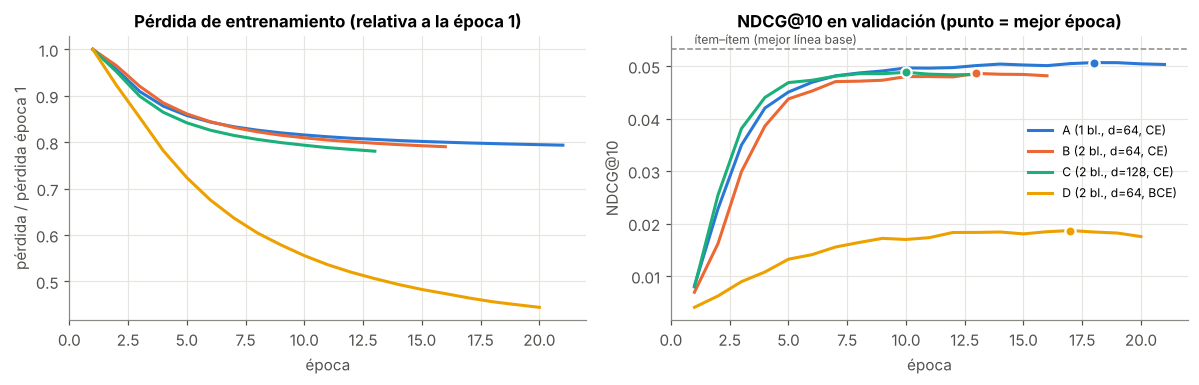

,bloques,d,cabezas,pérdida,mejor época,épocas corridas,HR@10 val,NDCG@10 val,parámetros,min. entrenamiento
A,1,64,1,CE,18,21,0.0818,0.0507,"1,167,872",38.2
B,2,64,1,CE,13,16,0.0786,0.0486,"1,193,088",26.8
C,2,128,2,CE,10,13,0.0788,0.0488,"2,484,480",32.0
D,2,64,1,BCE,17,20,0.0354,0.0187,"1,193,088",7.9


Configuración elegida en validación: A


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
colores = dict(zip(CONFIGS, [AZUL, NARANJO, AQUA, AMARILLO]))
for clave in CONFIGS:
    cv = HIST[clave]["curvas"]
    etiqueta = f"{clave} ({CONFIGS[clave]['bloques']} bl., d={CONFIGS[clave]['d']}, {CONFIGS[clave]['perdida'].upper()})"
    ax[1].plot(cv["epoca"], cv["ndcg10_val"], color=colores[clave], lw=2, label=etiqueta)
    me = HIST[clave]["mejor_epoca"]
    ax[1].scatter([me], [cv["ndcg10_val"][me - 1]], color=colores[clave], s=45, zorder=3, edgecolor="white", linewidth=1.5)
    perd = np.array(cv["perdida"]); ax[0].plot(cv["epoca"], perd / perd[0], color=colores[clave], lw=2, label=etiqueta)
ax[0].set(title="Pérdida de entrenamiento (relativa a la época 1)", xlabel="época", ylabel="pérdida / pérdida época 1")
ax[1].axhline(resultados_val["Ítem–ítem coseno"]["NDCG@10"], color=GRIS, ls="--", lw=1)
ax[1].text(1, resultados_val["Ítem–ítem coseno"]["NDCG@10"] * 1.02, "ítem–ítem (mejor línea base)", fontsize=8, color="#52514e")
ax[1].set(title="NDCG@10 en validación (punto = mejor época)", xlabel="época", ylabel="NDCG@10")
ax[1].legend(frameon=False, fontsize=8, loc="center right", bbox_to_anchor=(1.0, 0.56))
plt.tight_layout(); plt.show()

arquitectura = lambda c: {k: CONFIGS[c][k] for k in ("d", "bloques", "cabezas", "dropout")}
params = {c: sum(p.numel() for p in SASRec(N_ITEMS, maxlen=MAXLEN, **arquitectura(c)).parameters()) for c in CONFIGS}
tabla_cfg = pd.DataFrame({
    c: {"bloques": CONFIGS[c]["bloques"], "d": CONFIGS[c]["d"], "cabezas": CONFIGS[c]["cabezas"], "pérdida": CONFIGS[c]["perdida"].upper(),
        "mejor época": HIST[c]["mejor_epoca"], "épocas corridas": len(HIST[c]["curvas"]["epoca"]),
        "HR@10 val": HIST[c]["curvas"]["hr10_val"][HIST[c]["mejor_epoca"] - 1],
        "NDCG@10 val": HIST[c]["curvas"]["ndcg10_val"][HIST[c]["mejor_epoca"] - 1],
        "parámetros": params[c], "min. entrenamiento": HIST[c]["segundos"] / 60} for c in CONFIGS}).T
MEJOR_CFG = tabla_cfg["NDCG@10 val"].astype(float).idxmax()
display(tabla_cfg.style.format({"HR@10 val": "{:.4f}", "NDCG@10 val": "{:.4f}", "parámetros": "{:,.0f}", "min. entrenamiento": "{:.1f}"})
        .highlight_max(subset=["NDCG@10 val"], color="#cde2fb"))
print(f"Configuración elegida en validación: {MEJOR_CFG}")

In [20]:
# Modelo final: la configuración elegida se guarda como modelos/sasrec.pt (lo que pide el enunciado)
import shutil
sasrec = modelos_sasrec[MEJOR_CFG]
if sasrec is None:   # por si solo existe modelos/sasrec.pt
    sasrec = SASRec(N_ITEMS, maxlen=MAXLEN, **arquitectura(MEJOR_CFG))
    sasrec.load_state_dict(torch.load(MODELOS / "sasrec.pt", map_location="cpu")["estado"]); sasrec.eval()
elif (MODELOS / f"sasrec_{MEJOR_CFG}.pt").exists():
    shutil.copy(MODELOS / f"sasrec_{MEJOR_CFG}.pt", MODELOS / "sasrec.pt")
print(f"modelos/sasrec.pt = configuración {MEJOR_CFG} · {(MODELOS / 'sasrec.pt').stat().st_size / 1e6:.1f} MB (< 100 MB)")

def score_sasrec_factory(modelo):
    modelo.eval()
    @torch.no_grad()
    def f(H):
        return modelo.puntajes(lote(H)).numpy() + desempate
    return f

resultados_val["SASRec"], _ = evaluar(score_sasrec_factory(sasrec), hist_val, val_t)
ajuste["SASRec"] = HIST[MEJOR_CFG]["segundos"]
parametros["SASRec"] = params[MEJOR_CFG]

print("Validación con la función común `evaluar` (mismas reglas que las líneas base):")
pd.DataFrame(resultados_val).T[COLS]

modelos/sasrec.pt = configuración A · 4.7 MB (< 100 MB)


Validación con la función común `evaluar` (mismas reglas que las líneas base):


,HR@5,HR@10,HR@20,NDCG@5,NDCG@10,NDCG@20,MRR,Cobertura@10
Popularidad global,0.0041,0.0096,0.0158,0.0025,0.0042,0.0058,0.0046,0.0008
Popularidad reciente,0.0087,0.0158,0.0277,0.0053,0.0076,0.0106,0.0084,0.0285
Reglas de asociación,0.0568,0.0738,0.0868,0.0399,0.0454,0.0487,0.0389,0.2181
Ítem–ítem coseno,0.0636,0.0779,0.0925,0.0486,0.0532,0.0569,0.0482,0.9217
SASRec,0.0596,0.0818,0.1115,0.0435,0.0507,0.0581,0.0466,0.7029


## 7. Comparación final en prueba (una sola vez)
Con todo elegido en validación (ventana de popularidad, umbrales de las reglas, λ y configuración de SASRec), cada modelo
predice el último ítem de cada clienta viendo todo lo anterior.

In [21]:
modelos_test = {
    "Popularidad global": score_pop,
    "Popularidad reciente": score_reciente_factory(fecha_test, W_BEST),
    "Reglas de asociación": score_reglas_factory(REGLAS),
    "Ítem–ítem coseno": score_knn_factory(LAM_BEST),
    "SASRec": score_sasrec_factory(sasrec),
}
res_test, ranks_test = {}, {}
for m, fn in modelos_test.items():
    res_test[m], ranks_test[m] = evaluar(fn, hist_test, test_t)

tabla = pd.DataFrame(res_test).T[COLS + ["ms_por_1000_usuarias"]]
tabla["ajuste (s)"] = pd.Series(ajuste)
tabla["parámetros"] = pd.Series(parametros)
tabla.style.format({**{c: "{:.4f}" for c in COLS}, "Cobertura@10": "{:.1%}", "ms_por_1000_usuarias": "{:,.0f}",
                    "ajuste (s)": "{:,.1f}", "parámetros": "{:,.0f}"}).highlight_max(subset=COLS, color="#cde2fb")

,HR@5,HR@10,HR@20,NDCG@5,NDCG@10,NDCG@20,MRR,Cobertura@10,ms_por_1000_usuarias,ajuste (s),parámetros
Popularidad global,0.0034,0.0087,0.0148,0.0019,0.0037,0.0052,0.0040,0.1%,238,0.0,"17,801"
Popularidad reciente,0.0088,0.0165,0.0296,0.0055,0.0080,0.0113,0.0089,2.8%,288,0.1,"3,293,185"
Reglas de asociación,0.0627,0.0818,0.0958,0.0448,0.0510,0.0545,0.0436,21.8%,577,6.7,"17,199"
Ítem–ítem coseno,0.0707,0.0872,0.1035,0.0550,0.0603,0.0645,0.0548,91.4%,298,1.1,"1,727,604"
SASRec,0.0666,0.0895,0.1173,0.0495,0.0568,0.0638,0.0522,67.8%,376,"2,293.1","1,167,872"


Guardado ../data/metricas.csv (10 filas)


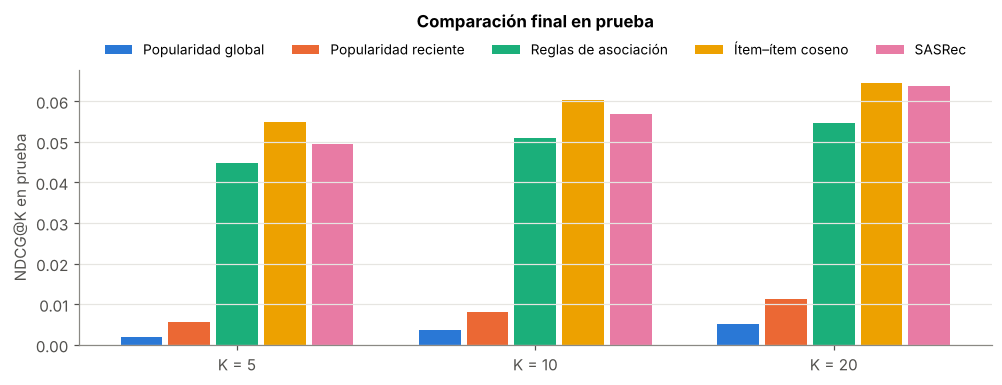

In [22]:
filas = []
for conj, res in (("validacion", resultados_val), ("prueba", res_test)):
    for m, r in res.items():
        filas.append({"modelo": m, "conjunto": conj, **{c: r[c] for c in COLS},
                      "ms_por_1000_usuarias": r["ms_por_1000_usuarias"],
                      "ajuste_s": ajuste[m], "parametros": parametros[m]})
metricas = pd.DataFrame(filas)
metricas.to_csv(DATA / "metricas.csv", index=False)
print(f"Guardado {DATA / 'metricas.csv'} ({len(metricas)} filas)")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
xk = np.arange(len(KS)); ancho = 0.16
for i, (m, fila) in enumerate(tabla[[f"NDCG@{k}" for k in KS]].iterrows()):
    ax.bar(xk + (i - 2) * ancho, fila.values, width=ancho - 0.02, label=m)
ax.set_xticks(xk, [f"K = {k}" for k in KS]); ax.set_ylabel("NDCG@K en prueba")
ax.set_title("Comparación final en prueba", pad=28)
ax.legend(frameon=False, fontsize=9, ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

**Costo.** *Ajuste* es el tiempo de entrenamiento en CPU (para SASRec, solo la configuración elegida; las cuatro sumaron
el total de la tabla de la sección 6.5). *Inferencia* es el tiempo para puntuar y ordenar el catálogo completo para
1.000 clientas, dentro de la misma función `evaluar`. *Parámetros* son los números que guarda cada modelo.

## 8. Segmentos
HR@10 en prueba según:
- **Historial:** corto (≤ mediana de compras previas) o largo.
- **Ítem real:** popular (20 % de prendas más vendidas en entrenamiento) o cola larga.
- **Tipo de tarea:** *completar el carrito* (prueba el mismo día que validación) o *próxima visita* (otro día).

,modelo,Popularidad global,Popularidad reciente,Reglas de asociación,Ítem–ítem coseno,SASRec
segmento,usuarias,,,,,
Historial corto,19422,0.0107,0.0159,0.0948,0.0955,0.0986
Historial largo,16746,0.0064,0.0172,0.0667,0.0776,0.0789
Ítem popular,18256,0.0173,0.0289,0.1332,0.1182,0.1320
Ítem cola larga,17912,0.0000,0.0039,0.0294,0.0556,0.0461
Completar carrito,25385,0.0094,0.0163,0.1055,0.1155,0.1157
Próxima visita,10783,0.0072,0.0170,0.0260,0.0206,0.0277


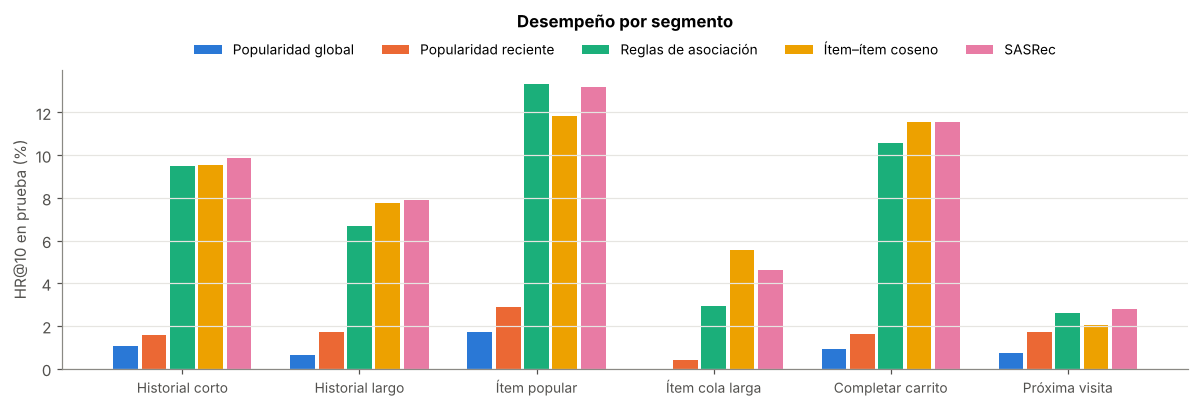

In [23]:
largo_hist = np.array([len(h) for h in hist_test])
umbral_pop = np.sort(pop[1:])[::-1][int(0.2 * N_ITEMS)]
segmentos = {
    "Historial corto": largo_hist <= np.median(largo_hist),
    "Historial largo": largo_hist > np.median(largo_hist),
    "Ítem popular": pop[test_t] > umbral_pop,
    "Ítem cola larga": pop[test_t] <= umbral_pop,
    "Completar carrito": mismo_carrito,
    "Próxima visita": ~mismo_carrito,
}
seg = []
for s_nombre, mask in segmentos.items():
    for m, r in ranks_test.items():
        seg.append({"segmento": s_nombre, "usuarias": int(mask.sum()), "modelo": m,
                    "HR@10": np.mean(r[mask] <= 10),
                    "NDCG@10": np.mean(np.where(r[mask] <= 10, 1 / np.log2(r[mask] + 1), 0))})
seg = pd.DataFrame(seg)
tabla_seg = seg.pivot(index=["segmento", "usuarias"], columns="modelo", values="HR@10").reindex(
    [(s, int(m.sum())) for s, m in segmentos.items()])[list(modelos_test)]
display(tabla_seg.style.format("{:.4f}").highlight_max(axis=1, color="#cde2fb"))

fig, ax = plt.subplots(figsize=(11, 3.8))
xs = np.arange(len(segmentos)); ancho = 0.16
for i, m in enumerate(modelos_test):
    ax.bar(xs + (i - 2) * ancho, tabla_seg[m].values * 100, width=ancho - 0.02, label=m)
ax.set_xticks(xs, list(segmentos), fontsize=9); ax.set_ylabel("HR@10 en prueba (%)")
ax.set_title("Desempeño por segmento", pad=28)
ax.legend(frameon=False, fontsize=9, ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

**Lectura de los segmentos:** SASRec gana o empata en 5 de los 6 segmentos, pero por poco.
- **Próxima visita** (otro día): SASRec 2,8 % vs reglas 2,6 % e ítem–ítem 2,1 % (+35 % sobre ítem–ítem). Es su ventaja más clara y justo donde importa el orden entre días, aunque el nivel absoluto es bajo.
- **Completar carrito:** empate entre SASRec e ítem–ítem (11,6 %).
- **Historial corto y largo:** SASRec levemente arriba (9,9 % y 7,9 %).
- **Cola larga:** gana ítem–ítem (5,6 % vs 4,6 %). La softmax de SASRec favorece prendas más vendidas, coherente con su menor cobertura (68 % vs 91 %).
- **Ítem popular:** reglas (13,3 %) y SASRec (13,2 %) empatan.

## 9. Tres clientas: historial, recomendación y pesos de atención
Para tres clientas con perfiles distintos se muestra su historial reciente, el top 5 de SASRec y **a qué compras previas
atendió** el modelo al recomendar.

**Cómo se leen los pesos.** El modelo elegido (configuración A) tiene **1 bloque y 1 cabeza**, así que no hay nada que
promediar: cada barra es el peso α de esa única cabeza en la **fila de la última posición** del historial, que es el vector
con que se puntúan las 17.801 prendas. Son los pesos después del softmax con las máscaras causal y de relleno, en modo
evaluación (sin dropout), y **suman 1 sobre todas las compras del historial** (hasta 50). El gráfico muestra las 8 más
recientes, así que sus barras pueden sumar menos de 1. Con más bloques o cabezas, el código usa el último bloque y promedia
las cabezas. Un peso alto dice dónde miró el modelo, no por qué la clienta eligió la prenda.


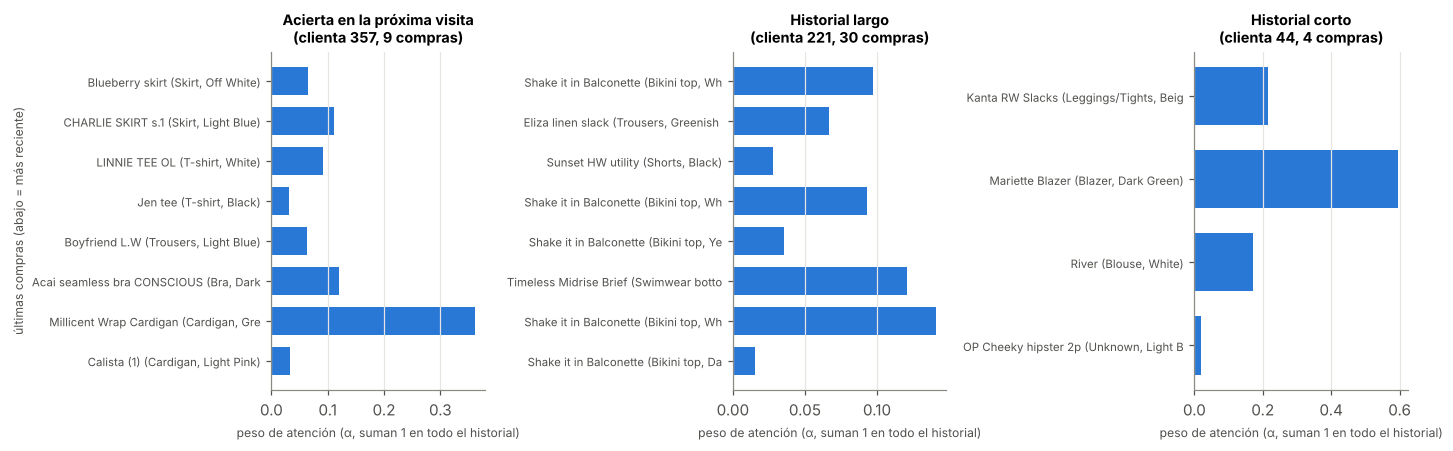


■ Acierta en la próxima visita — clienta 357
  Últimas 4 compras:  Boyfriend L.W (Trousers, Light Blue) | Acai seamless bra CONSCIOUS (Bra, Dark Blue) | Millicent Wrap Cardigan (Cardigan, Grey) | Calista (1) (Cardigan, Light Pink)
  Compra real siguiente: Calista cardigan. (Cardigan, Black)  (posición 1 en el ranking de SASRec)
   1. Calista cardigan. (Cardigan, Black)   ← compra real
   2. Calista (1) (Cardigan, Light Grey)
   3. Millicent Wrap Cardigan (Cardigan, Beige)
   4. Calista cardigan. (Cardigan, Off White)
   5. Calista (1) (Cardigan, Light Orange)

■ Historial largo — clienta 221
  Últimas 4 compras:  Shake it in Balconette (Bikini top, Yellow) | Timeless Midrise Brief (Swimwear bottom, White) | Shake it in Balconette (Bikini top, White) | Shake it in Balconette (Bikini top, Dark Green)
  Compra real siguiente: Timeless Midrise Brief (Swimwear bottom, Yellow)  (posición 4 en el ranking de SASRec)
   1. Timeless Midrise Brief (Swimwear bottom, Dark Green)
   2. Shake it in 

In [24]:
@torch.no_grad()
def atencion_ultima(modelo, h):
    s = lote([h]); _, pesos = modelo(s)
    w = pesos[-1][0].mean(0)[-1].numpy()   # último bloque · promedio de cabezas (A tiene 1) · fila de la última posición
    n = min(len(h), MAXLEN)
    return w[-n:]                                         # pesos sobre las n compras reales (la última al final)

def top_sasrec(h, k=5):
    sc = score_sasrec_factory(sasrec)([h])[0].astype(np.float64); sc[0] = -np.inf; sc[h] = -np.inf
    return np.argsort(-sc)[:k]

r_s = ranks_test["SASRec"]
casos = {
    "Acierta en la próxima visita": int(np.where((r_s <= 5) & ~mismo_carrito & (largo_hist >= 8))[0][0]),
    "Historial largo": int(np.where((r_s <= 10) & (largo_hist >= 30))[0][0]),
    "Historial corto": int(np.where((r_s <= 10) & (largo_hist <= 6))[0][0]),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (titulo, u) in zip(axes, casos.items()):
    h = hist_test[u]; w = atencion_ultima(sasrec, h)
    ult = min(8, len(w)); etiquetas = [nombre[x][:38] for x in h[-ult:]]
    ax.barh(range(ult), w[-ult:], color=AZUL, height=0.7)
    ax.set_yticks(range(ult), etiquetas, fontsize=7.5); ax.invert_yaxis()
    ax.set_title(f"{titulo}\n(clienta {u + 1}, {len(h)} compras)", fontsize=9.5)
    ax.set_xlabel("peso de atención (α, suman 1 en todo el historial)", fontsize=8); ax.grid(axis="y", visible=False)
axes[0].set_ylabel("últimas compras (abajo = más reciente)", fontsize=8)
plt.tight_layout(); plt.show()

for titulo, u in casos.items():
    h = hist_test[u]
    print(f"\n■ {titulo} — clienta {u + 1}")
    print("  Últimas 4 compras:  " + " | ".join(nombre[x] for x in h[-4:]))
    print(f"  Compra real siguiente: {nombre[test_t[u]]}  (posición {int(r_s[u])} en el ranking de SASRec)")
    for i, x in enumerate(top_sasrec(h), 1):
        print(f"   {i}. {nombre[x]}" + ("   ← compra real" if x == test_t[u] else ""))

**Lectura de la atención.** SASRec no mira siempre la última compra: mira la que define *qué está armando* la clienta.
- **Clienta 357:** el 36 % de la atención va al cardigan Millicent (penúltima compra). Recomienda cinco cardigans y acierta el Calista negro en el 1.er lugar.
- **Clienta 221** (30 compras): reparte la atención entre los tops de bikini y el calzón Timeless, y recomienda las piezas que completan los conjuntos. Acierta en el 4.º lugar.
- **Clienta 44** (4 compras): el 60 % de la atención va al blazer verde oscuro, y la 1.ª recomendación es la falda Katya verde oscuro que efectivamente compró: completa el traje.

Una bolsa de ítems no puede hacer esta selección. Dos cuidados: los pesos de atención muestran dónde mira el modelo, no prueban por qué decide; y, como ítem–ítem, a veces llena el top con la misma prenda en otros colores.

## 10. Embeddings de prendas por categoría
Cada prenda tiene un vector de dimensión *d* aprendido por SASRec **sin ver su categoría**. Si el modelo captó algo de la
moda, prendas del mismo grupo deberían quedar cerca. Se proyectan con t-SNE las prendas con ≥ 20 compras y se colorean por
grupo de producto; además se mide qué fracción de los 10 vecinos más cercanos (coseno) es del mismo grupo.

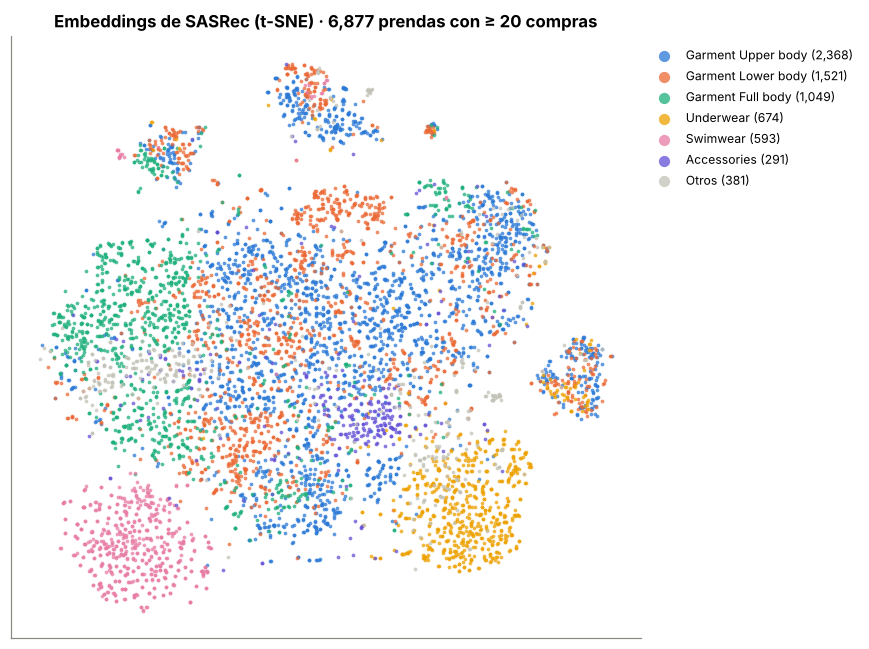

Vecinos (top 10 por coseno) del mismo grupo de producto: 68.6%  vs  21.1% si fuera al azar (3.3 veces)
Vecinos del mismo tipo de prenda: 48.0%  vs  6.2% al azar (7.8 veces)


In [25]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

E = sasrec.item.weight.detach().numpy()
frecuentes = np.where(pop >= 20)[0]; frecuentes = frecuentes[frecuentes > 0]
grupo = mapa.set_index("item_idx").loc[frecuentes, "product_group_name"].to_numpy(dtype=object)
principales = pd.Series(grupo).value_counts().index[:6]
grupo_graf = np.where(np.isin(grupo, principales), grupo, "Otros")

Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(PCA(30, random_state=SEED).fit_transform(E[frecuentes]))
fig, ax = plt.subplots(figsize=(8, 6))
for g, col in zip(list(principales) + ["Otros"], [AZUL, NARANJO, AQUA, AMARILLO, MAGENTA, VIOLETA, "#c3c2b7"]):
    m = grupo_graf == g
    ax.scatter(Z[m, 0], Z[m, 1], s=6, color=col, label=f"{g} ({m.sum():,})", alpha=0.75, linewidths=0)
ax.legend(frameon=False, fontsize=8, markerscale=3, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set(title=f"Embeddings de SASRec (t-SNE) · {len(frecuentes):,} prendas con ≥ 20 compras", xticks=[], yticks=[])
ax.grid(False); plt.tight_layout(); plt.show()

En = E[frecuentes] / np.linalg.norm(E[frecuentes], axis=1, keepdims=True)
vecinos = np.argsort(-(En @ En.T), axis=1)[:, 1:11]
mismo = (grupo[vecinos] == grupo[:, None]).mean()
esperado = (pd.Series(grupo).value_counts(normalize=True) ** 2).sum()
print(f"Vecinos (top 10 por coseno) del mismo grupo de producto: {mismo:.1%}  vs  {esperado:.1%} si fuera al azar ({mismo/esperado:.1f} veces)")
tipo_f = mapa.set_index("item_idx").loc[frecuentes, "product_type_name"].to_numpy(dtype=object)
mismo_t = (tipo_f[vecinos] == tipo_f[:, None]).mean(); esperado_t = (pd.Series(tipo_f).value_counts(normalize=True) ** 2).sum()
print(f"Vecinos del mismo tipo de prenda: {mismo_t:.1%}  vs  {esperado_t:.1%} al azar ({mismo_t/esperado_t:.1f} veces)")

**Lectura.** Sin ver ninguna categoría, SASRec agrupa las prendas: el 68,6 % de los 10 vecinos más cercanos de cada prenda es de su mismo grupo de producto (21,1 % al azar, 3,3 veces más) y el 48 % es del mismo tipo de prenda (6,2 % al azar, 7,8 veces). Trajes de baño, ropa interior y accesorios forman islas separadas. Las prendas de arriba y de abajo quedan mezcladas porque se compran juntas para armar un look: el espacio refleja **complementariedad**, no solo parecido.

## 11. Conclusión: ¿vale la pena el Transformer en este rubro?

**Sí, como complemento, no como reemplazo.**

| | SASRec | Ítem–ítem coseno | Reglas (Certamen 2) |
|---|---|---|---|
| HR@10 / HR@20 en prueba | **8,95 % / 11,7 %** | 8,72 % / 10,4 % | 8,18 % / 9,6 % |
| NDCG@10 / MRR en prueba | 0,057 / 0,052 | **0,060 / 0,055** | 0,051 / 0,044 |
| Próxima visita (HR@10) | **2,8 %** | 2,1 % | 2,6 % |
| Cobertura@10 | 68 % | **91 %** | 22 % |
| Entrenamiento (CPU) | 38 min (1 h 45 min con la búsqueda) | **1 s** | 6 s |
| Inferencia por 1.000 clientas | ≈ 0,34 s | ≈ 0,31 s | ≈ 0,57 s |

- **Exactitud:** SASRec acierta un poco más seguido (mejor HR@10 y HR@20), pero ítem–ítem ubica el acierto más arriba (mejor NDCG y MRR). La diferencia global es pequeña.
- **Dónde aporta:** en la próxima visita (+35 % sobre ítem–ítem) y en entender qué está armando la clienta (sección 9). Sus embeddings aprenden la estructura del catálogo sin verla (sección 10).
- **La pérdida fue decisiva:** con la BCE de un negativo del repositorio original, el NDCG@10 de validación cae a 0,019, 2,7 veces peor y por debajo de las líneas base de co-ocurrencia. Un segundo bloque o más dimensiones no ayudaron.
- **Costo:** unas 2.000 veces más tiempo de entrenamiento que ítem–ítem para una mejora modesta, y menos cobertura del catálogo.

**Recomendación para H&M:** un híbrido. Ítem–ítem para "Completa tu look" dentro del carrito, donde es igual de bueno y casi gratis, y SASRec para el correo de la semana (próxima visita), donde es el mejor. En ambos casos, un re-ranking que limite las variantes de color de una misma prenda. Los pesos de atención de SASRec son además el insumo natural para que el analista con IA de la Entrega 2 explique y cuestione cada recomendación.